# 06 — Segment Analysis (Step 7)

**Question:** Does the ad have the same effect on everyone, or more on some users and less on others?
If the effect varies (**heterogeneous treatment effect**), showing the ad to the right people beats showing it to everyone.
That is the motivation for uplift modeling (Step 8).

**Plan:**
1. Split important features into segments, compute lift + CI in each → forest plot
2. One heterogeneity test per feature (Cochran's Q)
3. Look at the effect across deciles of "baseline activity" (prognostic score)
4. Multiple testing: how many "significant" segments could appear by chance? (A/A simulation)

Remember the Step 5 warning: segments are small, so conversion results will be noisy. The focus is **visit**.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.stats.multitest import multipletests

from src.data import load_criteo, FEATURES, AD_COST, VISIT_VALUE
from src.stats_tests import feature_segments, segment_effects, heterogeneity_test, itt_effect
from src.uplift_models import prognostic_score

FIG = Path.cwd().parent / "reports" / "figures"
pd.set_option("display.float_format", lambda x: f"{x:,.5f}")
df = load_criteo()
T = df.treatment.values
overall = itt_effect(df.visit[T == 1].values, df.visit[T == 0].values)
BREAK_EVEN = AD_COST / VISIT_VALUE
print(df.shape, f"overall visit ITT = {overall['effect']*100:.3f} pp")

(1397959, 16) overall visit ITT = 1.067 pp


## 7.1 Choosing features and building segments

Take the features most correlated with visit. **f10 is dropped:** its default group is exactly the same users as f4's
(the same 1,336,939 users), so it is almost a duplicate.

Binning rule (`feature_segments`): if ≥ 50% of users sit on one "default" value, create `default / low / high` segments.
Otherwise use tertiles: `low / medium / high`. Plain quantiles fail here because ties collapse the bins.

In [2]:
corr = df[FEATURES].corrwith(df.visit).abs().sort_values(ascending=False)
SEG_FEATURES = [f for f in corr.index if f != "f10"][:7]
print("Selected:", SEG_FEATURES)

for f in SEG_FEATURES:
    df[f"seg_{f}"] = feature_segments(df[f])
pd.DataFrame({f: df[f"seg_{f}"].value_counts(sort=False) for f in SEG_FEATURES}).T

Selected: ['f9', 'f8', 'f4', 'f11', 'f3', 'f5', 'f6']


,default,high,low,medium
f9,"1,111,868.00000","137,645.00000","148,446.00000",NaN
f8,"730,522.00000","330,624.00000","336,813.00000",NaN
f4,"1,336,939.00000","26,207.00000","34,813.00000",NaN
f11,"1,377,472.00000","13,070.00000","7,417.00000",NaN
f3,"1,145,059.00000","125,419.00000","127,481.00000",NaN
f5,"1,323,683.00000","48,341.00000","25,935.00000",NaN
f6,NaN,"370,410.00000","491,037.00000","536,512.00000"


## 7.2 Visit lift in each segment

In [3]:
seg_tables, het_rows = {}, []
for f in SEG_FEATURES:
    tbl = segment_effects(df, f"seg_{f}", "visit")
    seg_tables[f] = tbl
    h = heterogeneity_test(tbl.effect.values, tbl.se.values)
    het_rows.append({"feature": f, "segments": len(tbl), "Q": h["Q"], "p_value": h["p_value"], "I²": h["I2"],
                     "min effect (pp)": tbl.effect.min() * 100, "max effect (pp)": tbl.effect.max() * 100})

seg_all = pd.concat(seg_tables, names=["feature", "segment"])
seg_all[["n", "rate_c", "rate_t", "effect", "ci_low", "ci_high", "rel_lift", "p_value", "exposure_rate", "cace"]]

n  rate_c  rate_t  effect  ci_low  ci_high  rel_lift  \
feature segment                                                               
f9      default  1111868 0.00529 0.00742 0.00213 0.00174  0.00252   0.40282   
        low       148446 0.06803 0.08588 0.01785 0.01421  0.02149   0.26236   
        high      137645 0.28720 0.34039 0.05319 0.04628  0.06011   0.18522   
f8      default   730522 0.00083 0.00149 0.00066 0.00046  0.00086   0.79386   
        low       336813 0.14957 0.18454 0.03497 0.03151  0.03843   0.23380   
        high      330624 0.01131 0.01438 0.00308 0.00206  0.00410   0.27218   
f4      default  1336939 0.02769 0.03612 0.00843 0.00763  0.00922   0.30439   
        low        34813 0.21483 0.26074 0.04591 0.03347  0.05835   0.21370   
        high       26207 0.36116 0.41245 0.05129 0.03468  0.06790   0.14201   
f11     default  1377472 0.03298 0.04268 0.00970 0.00884  0.01055   0.29404   
        low         7417 0.49288 0.55987 0.06699 0.03441  0.09957   0.13592   
        high       13070 0.35254 0.40463 0.05210 0.02872  0.07547   0.14778   
f3      default  1145059 0.02822 0.03026 0.00204 0.00119  0.00289   0.07224   
        low       127481 0.10893 0.17544 0.06651 0.06130  0.07171   0.61053   
        high      125419 0.06707 0.08681 0.01974 0.01577  0.02372   0.29440   
f5      default  1323683 0.03490 0.04212 0.00722 0.00633  0.00811   0.20689   
        low        25935 0.14363 0.24059 0.09696 0.08380  0.11011   0.67506   
        high       48341 0.08294 0.12678 0.04384 0.03654  0.05114   0.52854   
f6      low       491037 0.05374 0.07887 0.02514 0.02329  0.02699   0.46781   
        medium    536512 0.01508 0.01764 0.00256 0.00164  0.00348   0.16979   
        high      370410 0.05157 0.05398 0.00241 0.00043  0.00438   0.04665   

                 p_value  exposure_rate    cace  
feature segment                                  
f9      default  0.00000        0.01842 0.11560  
        low      0.00000        0.05918 0.30163  
        high     0.00000        0.15179 0.35045  
f8      default  0.00000        0.01369 0.04821  
        low      0.00000        0.09856 0.35481  
        high     0.00000        0.02120 0.14517  
f4      default  0.00000        0.02998 0.28108  
        low      0.00000        0.12071 0.38032  
        high     0.00000        0.22861 0.22435  
f11     default  0.00000        0.03292 0.29460  
        low      0.00006        0.34554 0.19387  
        high     0.00001        0.18349 0.28393  
f3      default  0.00000        0.00828 0.24616  
        low      0.00000        0.23527 0.28269  
        high     0.00000        0.08180 0.24136  
f5      default  0.00000        0.02636 0.27386  
        low      0.00000        0.31216 0.31061  
        high     0.00000        0.14675 0.29872  
f6      low      0.00000        0.08428 0.29826  
        medium   0.00000        0.01154 0.22187  
        high     0.01709        0.00685 0.35125

### Heterogeneity test (Cochran's Q)
H0: the effect is the same in every segment of this feature. One test **per feature**, which limits the multiple-testing problem.
I² = the share of the variation in effects that is real heterogeneity rather than noise.

In [4]:
het = pd.DataFrame(het_rows).set_index("feature")
het["p_bonferroni"] = np.minimum(het.p_value * len(het), 1)
het.sort_values("Q", ascending=False)

,segments,Q,p_value,I²,min effect (pp),max effect (pp),p_bonferroni
feature,,,,,,,
f3,3,633.63844,0.00000,0.99684,0.20386,6.65071,0.00000
f6,3,477.19490,0.00000,0.99581,0.24058,2.51384,0.00000
f8,3,395.00100,0.00000,0.99494,0.06599,3.49695,0.00000
f9,3,278.33013,0.00000,0.99281,0.21297,5.31943,0.00000
f5,3,271.09986,0.00000,0.99262,0.72199,9.69594,0.00000
f4,3,60.09221,0.00000,0.96672,0.84279,5.12896,0.00000
f11,3,24.46797,0.00000,0.91826,0.96975,6.69905,0.00003


## 7.3 Forest plot

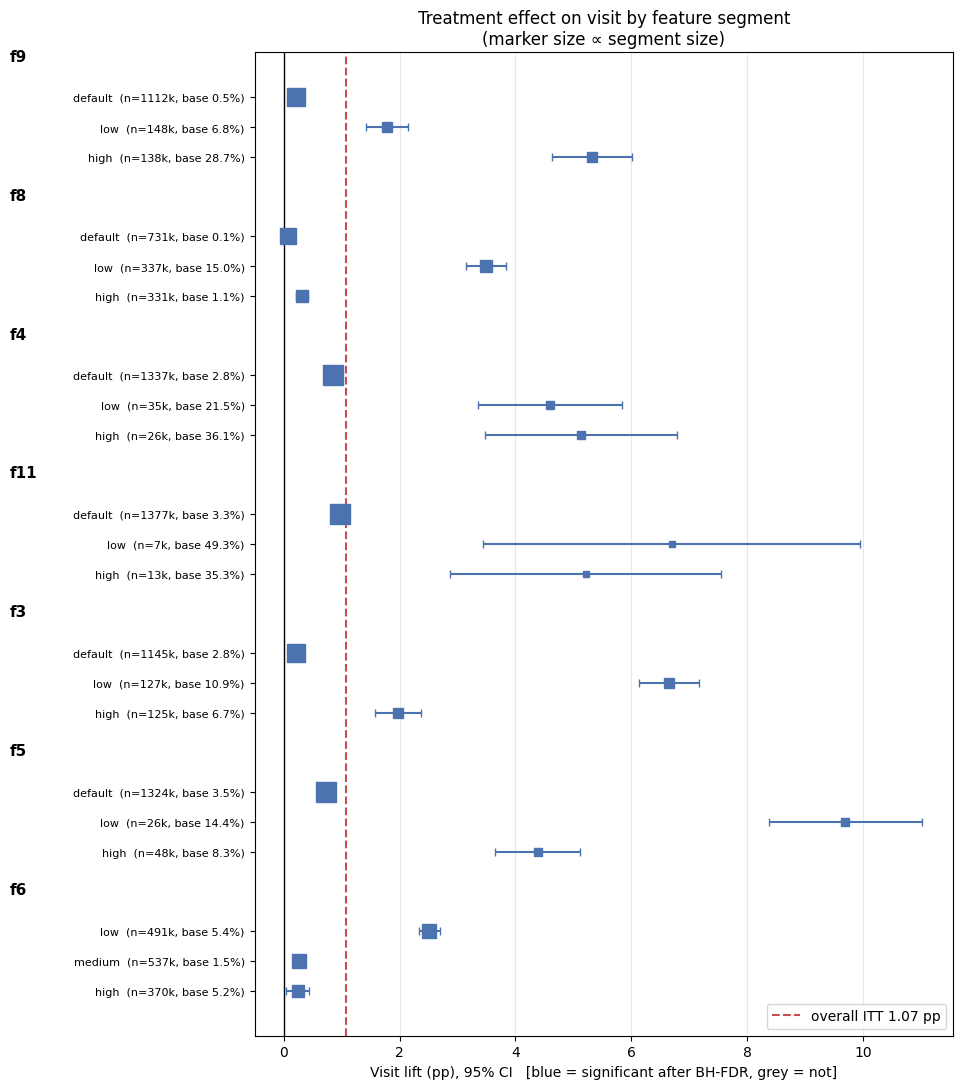

In [5]:
seg_all["p_bh"] = multipletests(seg_all.p_value, method="fdr_bh")[1]

fig, ax = plt.subplots(figsize=(10, 11))
y, ticks, labels = 0, [], []
for f in SEG_FEATURES:
    tbl = seg_all.loc[f]
    ax.text(-0.35, y + 0.2, f, fontweight="bold", fontsize=11, transform=ax.get_yaxis_transform())
    y -= 1
    for seg, r in tbl.iterrows():
        color = "#4C72B0" if r.p_bh < 0.05 else "#8C8C8C"
        ax.errorbar(r.effect * 100, y, xerr=[[(r.effect - r.ci_low) * 100], [(r.ci_high - r.effect) * 100]],
                    fmt="s", color=color, ms=4 + 10 * np.sqrt(r.share), capsize=3)
        ticks.append(y)
        labels.append(f"{seg}  (n={r.n/1000:.0f}k, base {r.rate_c:.1%})")
        y -= 1
    y -= 0.6
ax.axvline(overall["effect"] * 100, color="#C44E52", ls="--", lw=1.5, label=f"overall ITT {overall['effect']*100:.2f} pp")
ax.axvline(0, color="black", lw=1)
ax.set_yticks(ticks, labels, fontsize=8)
ax.set_xlabel("Visit lift (pp), 95% CI   [blue = significant after BH-FDR, grey = not]")
ax.set_title("Treatment effect on visit by feature segment\n(marker size ∝ segment size)")
ax.legend(loc="lower right")
ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
fig.savefig(FIG / "06_forest_plot.png", dpi=110, bbox_inches="tight")
plt.show()

## 7.4 Effect by baseline activity (prognostic score deciles)

Instead of looking at anonymized features one by one, combine all of them into one number: **how likely the user is to visit without ads**.
The model is trained only on control (the prognostic score from Step 6), so it does not "leak" the treatment effect.
Then split users into 10 equal deciles and measure the effect in each.

Bonus: conditioning on this score also largely controls the Step 6 imbalance inside each decile.

In [6]:
df["prog"] = prognostic_score(df, FEATURES, "visit")
df["prog_decile"] = pd.qcut(df.prog.rank(method="first"), 10, labels=[f"D{i}" for i in range(1, 11)])
dec = segment_effects(df, "prog_decile", "visit")
dec["mean_score"] = df.groupby("prog_decile", observed=True).prog.mean()
h_dec = heterogeneity_test(dec.effect.values, dec.se.values)
print(f"Cochran's Q = {h_dec['Q']:.0f}, df = {h_dec['df']}, p = {h_dec['p_value']:.1e}, I² = {h_dec['I2']:.0%}")
dec[["n", "mean_score", "rate_c", "rate_t", "effect", "ci_low", "ci_high", "rel_lift", "exposure_rate", "cace"]]

Cochran's Q = 397, df = 9, p = 5.4e-80, I² = 98%


,n,mean_score,rate_c,rate_t,effect,ci_low,ci_high,rel_lift,exposure_rate,cace
segment,,,,,,,,,,
D1,139796,0.00029,0.00060,0.00050,-0.00010,-0.00049,0.00029,-0.17153,0.00119,-0.08651
D2,139796,0.00037,0.00036,0.00056,0.00019,-0.00011,0.00049,0.52202,0.00148,0.12910
D3,139796,0.00044,0.00047,0.00088,0.00041,0.00009,0.00074,0.87434,0.00220,0.18768
D4,139796,0.00058,0.00037,0.00132,0.00095,0.00063,0.00127,2.55797,0.01437,0.06587
D5,139796,0.00117,0.00133,0.00239,0.00106,0.00050,0.00163,0.79822,0.02609,0.04069
D6,139795,0.00348,0.00378,0.00466,0.00087,-0.00003,0.00178,0.23106,0.01698,0.05146
D7,139796,0.00639,0.00658,0.00877,0.00219,0.00100,0.00339,0.33362,0.02025,0.10837
D8,139796,0.01546,0.01664,0.02161,0.00497,0.00304,0.00689,0.29847,0.04125,0.12043
D9,139796,0.05186,0.05215,0.07039,0.01824,0.01487,0.02161,0.34971,0.08098,0.22521


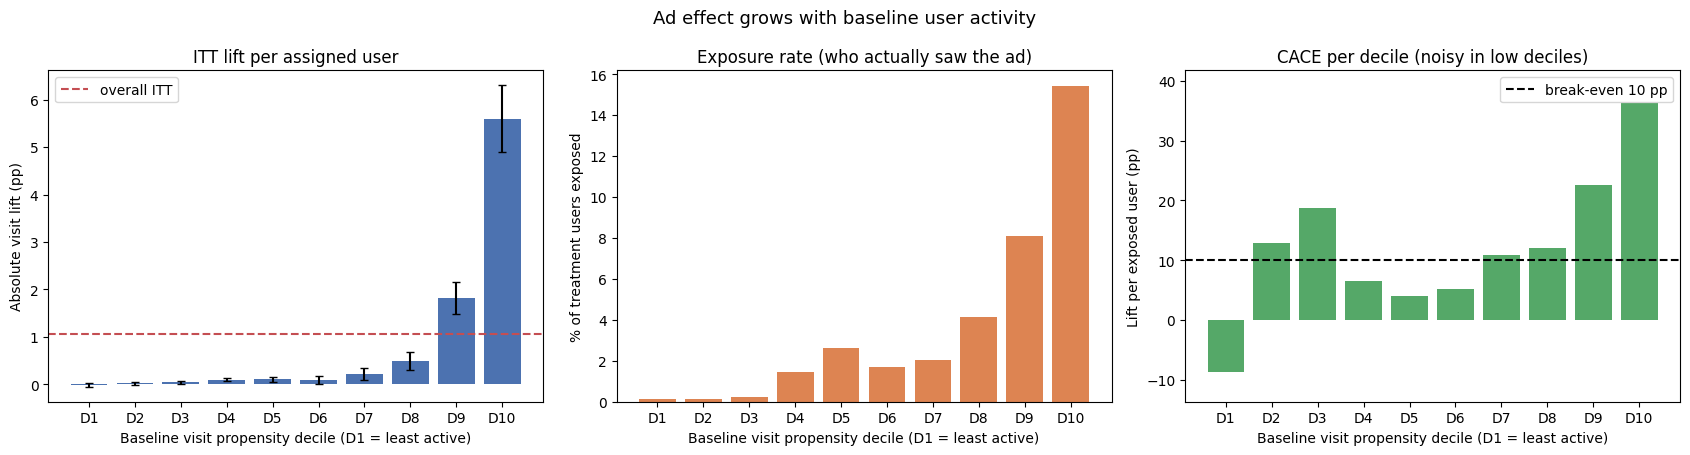

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
x = np.arange(10)
ax = axes[0]
ax.bar(x, dec.effect * 100, yerr=[(dec.effect - dec.ci_low) * 100, (dec.ci_high - dec.effect) * 100],
       color="#4C72B0", capsize=3)
ax.axhline(overall["effect"] * 100, color="#C44E52", ls="--", label="overall ITT")
ax.set_xticks(x, dec.index)
ax.set_ylabel("Absolute visit lift (pp)")
ax.set_title("ITT lift per assigned user")
ax.legend()

ax = axes[1]
ax.bar(x, dec.exposure_rate * 100, color="#DD8452")
ax.set_xticks(x, dec.index)
ax.set_ylabel("% of treatment users exposed")
ax.set_title("Exposure rate (who actually saw the ad)")

ax = axes[2]
ax.bar(x, dec.cace * 100, color="#55A868")
ax.axhline(BREAK_EVEN * 100, color="black", ls="--", label=f"break-even {BREAK_EVEN*100:.0f} pp")
ax.set_xticks(x, dec.index)
ax.set_ylabel("Lift per exposed user (pp)")
ax.set_title("CACE per decile (noisy in low deciles)")
ax.set_ylim(bottom=min(0, dec.cace.min() * 100) - 5, top=dec.cace.max() * 100 * 1.15)
ax.legend()
for a in axes:
    a.set_xlabel("Baseline visit propensity decile (D1 = least active)")
fig.suptitle("Ad effect grows with baseline user activity", fontsize=13)
fig.tight_layout()
fig.savefig(FIG / "06_prognostic_deciles.png", dpi=110)
plt.show()

In [8]:
top2 = dec.loc[["D9", "D10"]]
share_of_lift = (dec.effect * dec.n).loc[["D9", "D10"]].sum() / (dec.effect * dec.n).sum()
print(f"Top 2 deciles (20% users) contain {share_of_lift:.0%} of all incremental visits")
print(f"Bottom 5 deciles (50% users): avg lift {dec.effect.iloc[:5].mean()*100:.3f} pp")

Top 2 deciles (20% users) contain 88% of all incremental visits
Bottom 5 deciles (50% users): avg lift 0.050 pp


### Conversion (secondary): quintiles, because deciles would be too noisy

In [9]:
df["prog_q5"] = pd.qcut(df.prog.rank(method="first"), 5, labels=[f"Q{i}" for i in range(1, 6)])
conv_q = segment_effects(df, "prog_q5", "conversion")
conv_q[["n", "rate_c", "rate_t", "effect", "ci_low", "ci_high", "rel_lift", "p_value"]]

,n,rate_c,rate_t,effect,ci_low,ci_high,rel_lift,p_value
segment,,,,,,,,
Q1,279592,0.00003,0.00005,0.00002,-0.00004,0.00008,0.76758,0.49415
Q2,279592,0.00000,0.00007,0.00007,0.00004,0.00010,NaN,0.00006
Q3,279591,0.00007,0.00015,0.00008,-0.00001,0.00018,1.16487,0.08707
Q4,279592,0.00049,0.00068,0.00018,-0.00005,0.00042,0.37057,0.12817
Q5,279592,0.00957,0.01494,0.00537,0.00430,0.00644,0.56087,0.00000


## 7.5 Multiple testing: how many "significant" segments appear by chance?

We tested ~20 feature segments + 10 deciles above. At α = 0.05, ~5% of tests come out "significant" even with no real effect.

**A/A simulation:** shuffle the treatment labels (now the true effect = 0) and run the same segment analysis. Anything "significant" is a false positive.

In [10]:
rng = np.random.default_rng(7)
seg_cols = [f"seg_{f}" for f in SEG_FEATURES] + ["prog_decile"]
fp_raw, fp_bh, n_tests = [], [], None
for s in range(50):
    sh = df[seg_cols + ["visit", "exposure"]].copy()
    sh["treatment"] = rng.permutation(T)
    ps = np.concatenate([segment_effects(sh, c, "visit").p_value.values for c in seg_cols])
    n_tests = len(ps)
    fp_raw.append((ps < 0.05).sum())
    fp_bh.append(multipletests(ps, method="fdr_bh")[0].sum())
print(f"{n_tests} segment tests per run, 50 A/A runs (no real effect):")
print(f"  raw p < 0.05:  avg {np.mean(fp_raw):.2f} false positives per run, "
      f"{np.mean(np.array(fp_raw) > 0):.0%} of runs had at least one")
print(f"  BH-FDR 5%:     avg {np.mean(fp_bh):.2f} false positives per run, "
      f"{np.mean(np.array(fp_bh) > 0):.0%} of runs had at least one")

31 segment tests per run, 50 A/A runs (no real effect):
  raw p < 0.05:  avg 1.64 false positives per run, 70% of runs had at least one
  BH-FDR 5%:     avg 0.30 false positives per run, 10% of runs had at least one


In [11]:
real_ps = np.concatenate([seg_all.p_value.values, dec.p_value.values])
print(f"Real data: {(real_ps < 0.05).sum()} / {len(real_ps)} segments significant at raw 0.05, "
      f"{multipletests(real_ps, method='fdr_bh')[0].sum()} after BH-FDR, "
      f"{(real_ps < 0.05 / len(real_ps)).sum()} after Bonferroni")

Real data: 28 / 31 segments significant at raw 0.05, 28 after BH-FDR, 26 after Bonferroni


## 7.6 Caveats

1. **Multiple testing:** looking at many segments surfaces some "interesting" patterns by chance alone. That is why we used
   a BH-FDR correction, per-feature heterogeneity tests, and an A/A simulation.
2. **Segments are correlated:** the features are related to each other (Step 2), so f9-high and f8-low may be the same people.
   Do not treat separate segments as independent "insights".
3. **Imbalance inside feature segments:** the Step 6 imbalance can exist inside a segment too. Prognostic deciles largely control it,
   because they condition directly on baseline activity.
4. **One feature at a time:** this analysis does not capture interactions. The Step 8 uplift models use all features together.

## Key takeaways (Step 7)

1. **The effect is not the same for everyone, and the differences are large.** Every feature's Cochran's Q test gives p < 0.0001, with I² of 92–99%.
   Almost all of the variation between segments is real, not noise.
2. **Users with "default" feature values barely respond to the ad:**
   - f3 default (82% of users): only +0.20 pp, while f3 low (9% of users): **+6.65 pp**, i.e. 33× more
   - f8 default (52% of users): +0.07 pp; f9 default (80% of users): +0.21 pp
   - The largest lift is in f5 low (+9.7 pp, 2% of users)
3. **Baseline activity shows the clearest pattern (prognostic deciles):**
   - D1–D5 (50% of users): average lift only **0.05 pp**, practically zero
   - D10 (10% of users): **+5.6 pp**; D9: +1.8 pp
   - **The top 20% of users account for 88% of incremental visits.**
4. **Exposure is concentrated on active users too:** 15.4% of D10 treatment users saw the ad vs only ~0.2% in D1–D3.
   That makes the CACE in low deciles very noisy. But D4–D6 have a CACE of ~4–7 pp, **below** the 10 pp break-even.
   So **even under per-impression pricing**, showing ads to less active users loses money. D9–D10 (22–36 pp) are clearly profitable.
5. **Relative vs absolute:** low deciles show large relative lifts (e.g. D4 +256%), but on a tiny base.
   Money comes from absolute incremental visits, so business decisions should use absolute lift.
6. **Conversion** (quintiles): only Q5 (top 20%) shows a clear effect (+0.54 pp). In Q1–Q4 the CIs cross zero, as Step 5 predicted.
7. **Multiple testing:** in the A/A simulation (no real effect), 70% of runs had at least one false positive at raw p < 0.05,
   vs only 10% with BH-FDR. In the real data 28 of 31 segments stay significant after BH (26 after Bonferroni).
   The heterogeneity is real, not chance.

**Motivation for uplift modeling:** targeting only the top 20% "active" users captures ~88% of incremental visits
and saves a large share of the ad cost. But "active" ≠ "persuadable": D10's *relative* lift (18%) is lower than D9's (35%).
The Step 8 uplift models predict the **incremental effect** directly, not baseline activity. The real question is
whether they target better than the prognostic score.